# Osaka Bay: Benthic Analysis & Hypoxia Machine Learning (Annual Summer Mean)
This notebook aggregates the monitoring data to the annual summer mean (using strictly bottom WQ observations) and performs K-Means, GAMs, Mantel tests, and Random Forest classification to assess the drivers of benthic community structure under hypoxia.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score
import shap
import warnings
warnings.filterwarnings('ignore')

# Apply the global project style (SIS Mapping Standard)
plt.style.use('../project_style.mplstyle')


In [2]:
# 1. Environmental Data Aggregation (Annual Summer Mean)
# This implements the approved strategy: filtering to true bottom-layer WQ and aggregating to the annual summer mean

# Load Water Quality
wq_df = pd.read_feather('../data/processed/merged_gdf.feather')
wq_df['Pref_int'] = wq_df['prefectuei'].astype(int)
wq_summer = wq_df[
    (wq_df['Pref_int'].isin([27, 28])) & 
    (wq_df['surveymont'].isin([6, 7, 8, 9])) &
    (pd.to_numeric(wq_df['saisuipoin'], errors='coerce') == 2)
].copy()

wq_summer = wq_summer.rename(columns={'year': 'Year', 'surveymont': 'Month', 'Pref_int': 'Prefecture', 'renban': 'Station', 
                                      'do_': 'Bottom_DO', 'wtemp': 'Temperature', 'salt': 'Salinity', 'depth': 'Depth'})
for col in ['Bottom_DO', 'Temperature', 'Salinity', 'Depth']:
    wq_summer[col] = pd.to_numeric(wq_summer[col], errors='coerce')

wq_clean = wq_summer[['Year', 'Month', 'Prefecture', 'Station', 'Bottom_DO', 'Temperature', 'Salinity', 'Depth']].dropna(subset=['Bottom_DO']).copy()

# Load Sediment
sediment_df = pd.read_excel('../data/raw/benthos_data/bottom_2023.xlsx', sheet_name='底質_累積2023')
sediment_summer = sediment_df[(sediment_df['県コード'].isin([27, 28])) & (sediment_df['季節'].astype(str).str.startswith('2'))].copy()
sediment_summer = sediment_summer.rename(columns={'年': 'Year', '月': 'Month', '県コード': 'Prefecture', '連番': 'Station'})
chem_cols = ['TOC', '硫化物', 'ORP', 'pH']
for col in chem_cols:
    sediment_summer[col] = pd.to_numeric(sediment_summer[col], errors='coerce')
sediment_clean = sediment_summer[['Year', 'Month', 'Prefecture', 'Station'] + chem_cols].dropna(subset=['TOC']).copy()

# Load Benthos Metadata
benthos_df = pd.read_excel('../data/raw/benthos_data/benthos_2023.xlsx', sheet_name='底生生物_累積2023', skiprows=1)
benthos_osaka_hyogo = benthos_df[benthos_df['県コード'].isin([27, 28])].copy()
benthos_osaka_hyogo = benthos_osaka_hyogo.rename(columns={'県コード': 'Prefecture', '連番': 'Station'})
benthos_osaka_hyogo['Date'] = pd.to_datetime(benthos_osaka_hyogo['調査年月日'], errors='coerce')
benthos_osaka_hyogo['Year'] = benthos_osaka_hyogo['Date'].dt.year
benthos_events = benthos_osaka_hyogo[['Year', 'Prefecture', 'Station']].drop_duplicates().dropna().copy()

# Ensure integer keys
for df in [wq_clean, sediment_clean, benthos_events]:
    df['Year'] = df['Year'].astype(int)
    df['Prefecture'] = df['Prefecture'].astype(int)
    df['Station'] = df['Station'].astype(int)

# Aggregate to Annual Summer Means
wq_yearly = wq_clean.groupby(['Year', 'Prefecture', 'Station'])[['Bottom_DO', 'Temperature', 'Salinity', 'Depth']].mean().reset_index()
sediment_yearly = sediment_clean.groupby(['Year', 'Prefecture', 'Station'])[chem_cols].mean().reset_index()

# Merge
annual_merge = pd.merge(benthos_events, sediment_yearly, on=['Year', 'Prefecture', 'Station'], how='inner')
annual_merge = pd.merge(annual_merge, wq_yearly, on=['Year', 'Prefecture', 'Station'], how='inner')
print(f"Total Aligned Annual Summer Events: {len(annual_merge)}")


Total Aligned Annual Summer Events: 68


In [3]:
# 2. Benthos Community Matrix Formulation
# Melt wide to long, impute non-numeric as 1, and pivot to Site x Species

abundance_cols = [col for col in benthos_osaka_hyogo.columns if str(col).startswith('個体数')]
species_cols = [col for col in benthos_osaka_hyogo.columns if str(col).startswith('和名')]

valid_events = annual_merge[['Year', 'Prefecture', 'Station']].drop_duplicates()
benthos_filtered = pd.merge(benthos_osaka_hyogo, valid_events, on=['Year', 'Prefecture', 'Station'], how='inner')

# Ensure integers to avoid '2016.0' != '2016' when cast to string
for col in ['Year', 'Prefecture', 'Station']:
    benthos_filtered[col] = benthos_filtered[col].astype(int)

benthos_filtered['Site_ID'] = benthos_filtered['Year'].astype(str) + '_' + benthos_filtered['Prefecture'].astype(str) + '_' + benthos_filtered['Station'].astype(str)
annual_merge['Site_ID'] = annual_merge['Year'].astype(str) + '_' + annual_merge['Prefecture'].astype(str) + '_' + annual_merge['Station'].astype(str)

records = []
for idx, row in benthos_filtered.iterrows():
    site = row['Site_ID']
    for i in range(1, 63):
        sp_col = f'和名{i}'
        ab_col = f'個体数{i}'
        if sp_col in row and ab_col in row:
            species = row[sp_col]
            abundance = row[ab_col]
            if pd.notnull(species) and pd.notnull(abundance):
                records.append({'Site_ID': site, 'Species': species, 'Abundance': abundance})

long_df = pd.DataFrame(records)

# Impute non-numeric as 1
def clean_abundance(val):
    try:
        return float(val)
    except:
        return 1.0

long_df['Abundance'] = long_df['Abundance'].apply(clean_abundance)

community_matrix = long_df.pivot_table(index='Site_ID', columns='Species', values='Abundance', aggfunc='sum', fill_value=0)
print(f"Community Matrix Shape: {community_matrix.shape} (Sites x Species)")


Community Matrix Shape: (67, 315) (Sites x Species)


In [4]:
# 3. K-Means Clustering for Site Regime Classification
features = ['Bottom_DO', 'Temperature', 'Salinity', 'TOC', '硫化物', 'Depth']

# We must drop NaNs for KMeans and keep track of valid indices
valid_kmeans = annual_merge[features].dropna().index
X = annual_merge.loc[valid_kmeans, features].copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

silhouette_scores = []
K_range = range(2, 7)
for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(X_scaled)
    silhouette_scores.append(silhouette_score(X_scaled, labels))

optimal_k = K_range[np.argmax(silhouette_scores)]
print(f"Optimal K selected: {optimal_k}")

kmeans = KMeans(n_clusters=optimal_k, random_state=42)
annual_merge.loc[valid_kmeans, 'Cluster'] = kmeans.fit_predict(X_scaled)
annual_merge['Hypoxia'] = (annual_merge['Bottom_DO'] <= 2.0).astype(int)

crosstab = pd.crosstab(annual_merge.loc[valid_kmeans, 'Cluster'], annual_merge.loc[valid_kmeans, 'Hypoxia'], margins=True)
print("\nCross-Tabulation of Clusters against Hypoxia (Bottom_DO <= 2):")
display(crosstab)

centroids = scaler.inverse_transform(kmeans.cluster_centers_)
centroid_df = pd.DataFrame(centroids, columns=features)
print("\nCluster Centroids:")
display(centroid_df)


Optimal K selected: 2

Cross-Tabulation of Clusters against Hypoxia (Bottom_DO <= 2):


Hypoxia,0,1,All
Cluster,,,
0.0,0,1,1
1.0,49,16,65
All,49,17,66



Cluster Centroids:


,Bottom_DO,Temperature,Salinity,TOC,硫化物,Depth
0,1.700000,20.400000,25.380000,20.000000,1.90000,14.200000
1,4.215385,21.483077,31.970923,15.805026,0.63128,24.876923


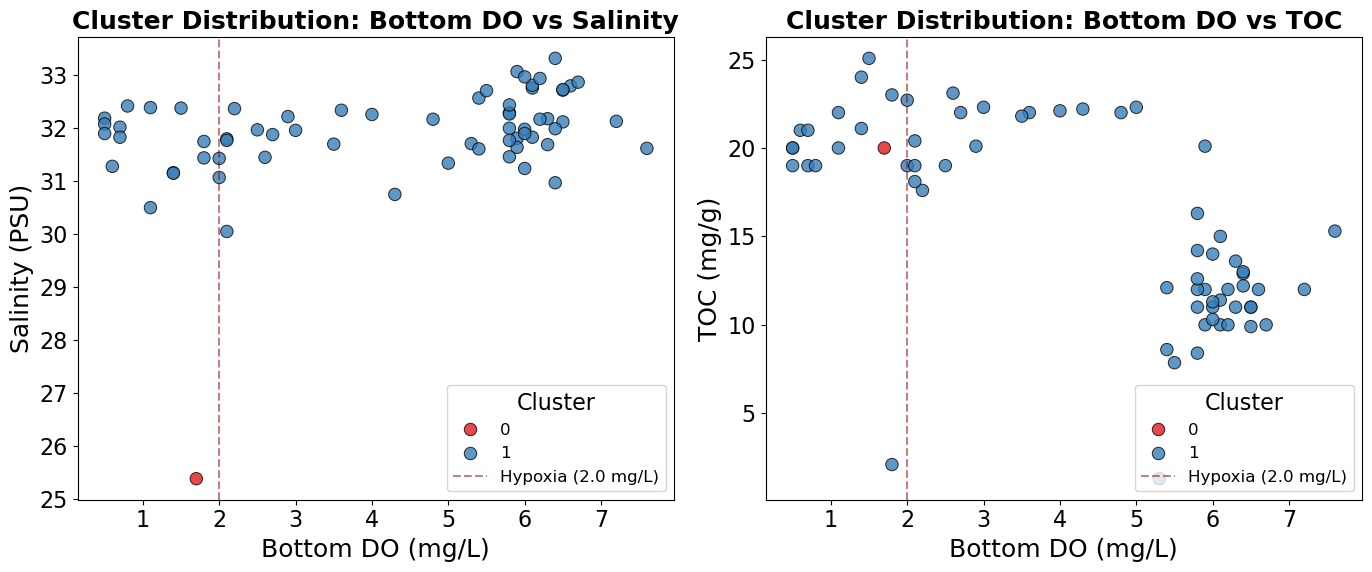

In [5]:
# Plot K-Means Clustering Results
df_plot = annual_merge.loc[valid_kmeans].copy()
df_plot['Cluster'] = df_plot['Cluster'].astype(int)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Subplot 1: Bottom DO vs Salinity (revealing the outlier cluster)
sns.scatterplot(
    data=df_plot, x='Bottom_DO', y='Salinity', hue='Cluster', palette='Set1', ax=axes[0],
    s=80, edgecolor='black', alpha=0.8
)
axes[0].set_title('Cluster Distribution: Bottom DO vs Salinity')
axes[0].set_xlabel('Bottom DO (mg/L)')
axes[0].set_ylabel('Salinity (PSU)')
axes[0].axvline(2.0, color='darkred', linestyle='--', alpha=0.5, label='Hypoxia (2.0 mg/L)')
axes[0].legend(title='Cluster')

# Subplot 2: Bottom DO vs TOC
sns.scatterplot(
    data=df_plot, x='Bottom_DO', y='TOC', hue='Cluster', palette='Set1', ax=axes[1],
    s=80, edgecolor='black', alpha=0.8
)
axes[1].set_title('Cluster Distribution: Bottom DO vs TOC')
axes[1].set_xlabel('Bottom DO (mg/L)')
axes[1].set_ylabel('TOC (mg/g)')
axes[1].axvline(2.0, color='darkred', linestyle='--', alpha=0.5, label='Hypoxia (2.0 mg/L)')
axes[1].legend(title='Cluster')

plt.tight_layout()
plt.show()

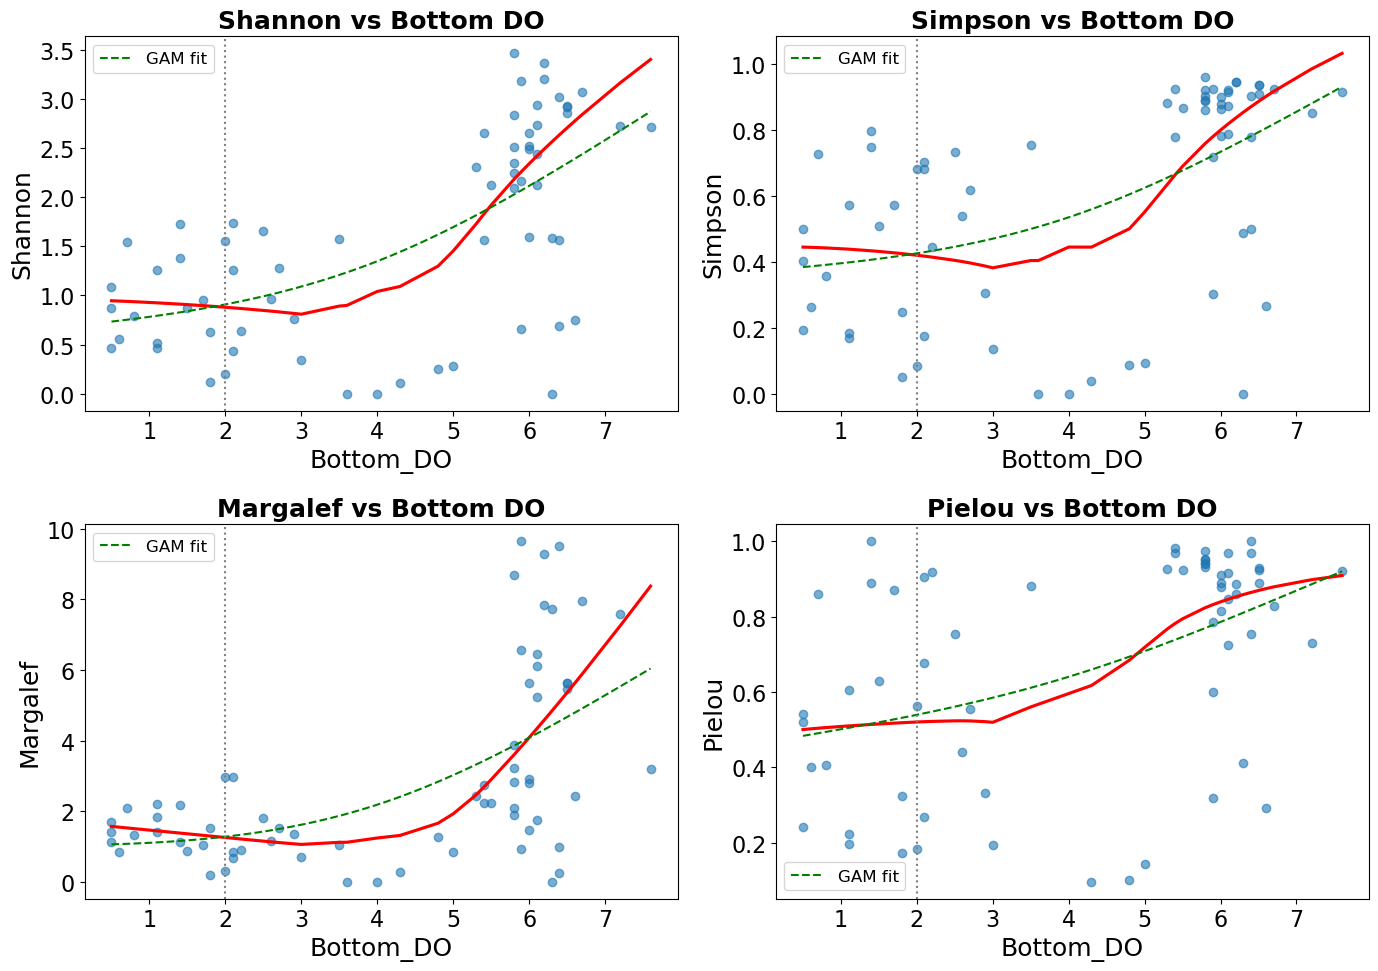

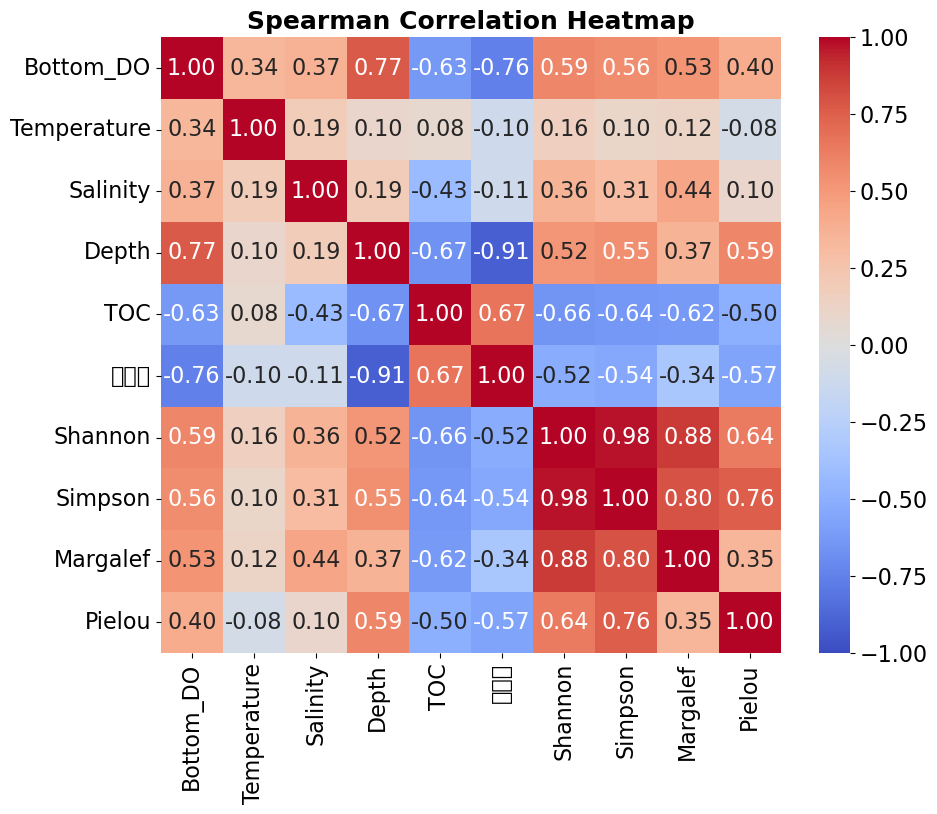

In [6]:
# 4. Benthic Diversity Indices & GAM Analysis
import warnings
from scipy.stats import entropy
try:
    from pygam import LinearGAM, s
    gam_available = True
except ImportError:
    gam_available = False
    print("pygam not found. Will use seaborn lowess curves instead.")

common_sites = community_matrix.index.intersection(annual_merge['Site_ID'])
comm_aligned = community_matrix.loc[common_sites]
env_aligned = annual_merge.set_index('Site_ID').loc[common_sites].copy()

N = comm_aligned.sum(axis=1)
S = (comm_aligned > 0).sum(axis=1)
P = comm_aligned.div(N, axis=0)

env_aligned['Shannon'] = P.apply(lambda row: entropy(row[row > 0], base=np.e), axis=1)
env_aligned['Simpson'] = 1 - (P**2).sum(axis=1)
env_aligned['Margalef'] = (S - 1) / np.log(N.replace(0, np.nan))
env_aligned['Pielou'] = env_aligned['Shannon'] / np.log(S.replace({0: np.nan, 1: np.nan}))

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
metrics = ['Shannon', 'Simpson', 'Margalef', 'Pielou']

for ax, metric in zip(axes.flatten(), metrics):
    sns.regplot(data=env_aligned, x='Bottom_DO', y=metric, lowess=True, 
                scatter_kws={'alpha': 0.6}, line_kws={'color': 'red'}, ax=ax)
    if gam_available:
        try:
            valid = env_aligned[['Bottom_DO', metric]].dropna()
            gam = LinearGAM(s(0, n_splines=5)).fit(valid['Bottom_DO'], valid[metric])
            XX = np.linspace(valid['Bottom_DO'].min(), valid['Bottom_DO'].max(), 100)
            ax.plot(XX, gam.predict(XX), color='green', linestyle='--', label='GAM fit')
            ax.legend()
        except:
            pass
    ax.set_title(f'{metric} vs Bottom DO')
    ax.axvline(2.0, color='gray', linestyle=':')

plt.tight_layout()
plt.show()

corr_vars = ['Bottom_DO', 'Temperature', 'Salinity', 'Depth', 'TOC', '硫化物'] + metrics
corr_matrix = env_aligned[corr_vars].corr(method='spearman')
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt=".2f")
plt.title("Spearman Correlation Heatmap")
plt.show()


In [7]:
# 5. Mantel Test for Community-Environment Correlation
from scipy.spatial.distance import pdist, squareform
from scipy.stats import spearmanr

def mantel_test(dist_matrix1, dist_matrix2, permutations=999):
    m1 = squareform(dist_matrix1)
    m2 = squareform(dist_matrix2)
    orig_stat, _ = spearmanr(m1, m2)
    
    n = dist_matrix1.shape[0]
    better = 0
    np.random.seed(42)
    for i in range(permutations):
        idx = np.random.permutation(n)
        permuted_m1 = dist_matrix1[idx, :][:, idx]
        stat, _ = spearmanr(squareform(permuted_m1), m2)
        if abs(stat) >= abs(orig_stat):
            better += 1
    return orig_stat, (better + 1) / (permutations + 1)

comm_dist = pdist(comm_aligned.values, metric='braycurtis')
env_vars = ['Bottom_DO', 'Temperature', 'Salinity', 'Depth', 'TOC']
print("Mantel Test Results (Spearman, 999 permutations):\n")

for var in env_vars:
    val = env_aligned[[var]].dropna()
    valid_sites = val.index
    c_dist = pdist(comm_aligned.loc[valid_sites].values, metric='braycurtis')
    e_dist = pdist(StandardScaler().fit_transform(val.values), metric='euclidean')
    r, p = mantel_test(squareform(c_dist), squareform(e_dist))
    print(f"{var:15s} | Mantel r: {r:.4f} | p-value: {p:.4f}")


Mantel Test Results (Spearman, 999 permutations):



Bottom_DO       | Mantel r: 0.2197 | p-value: 0.0010


Temperature     | Mantel r: 0.0404 | p-value: 0.4610


Salinity        | Mantel r: -0.0432 | p-value: 0.4440


Depth           | Mantel r: 0.3410 | p-value: 0.0010


TOC             | Mantel r: 0.2818 | p-value: 0.0010


Random Forest Performance:
Accuracy: 0.85
AUC-ROC: 0.9466666666666667

Classification Report:
               precision    recall  f1-score   support

           0       0.88      0.93      0.90        15
           1       0.75      0.60      0.67         5

    accuracy                           0.85        20
   macro avg       0.81      0.77      0.78        20
weighted avg       0.84      0.85      0.84        20



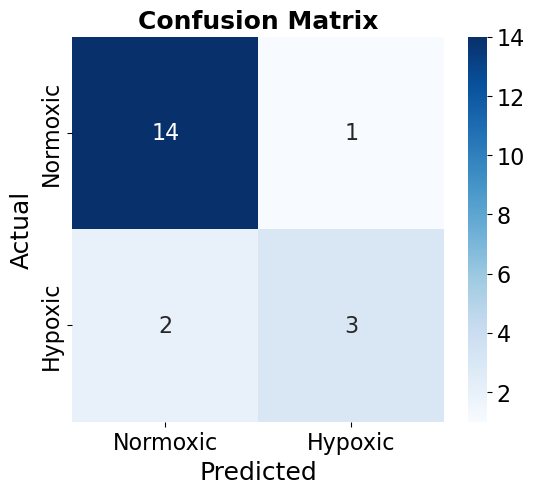

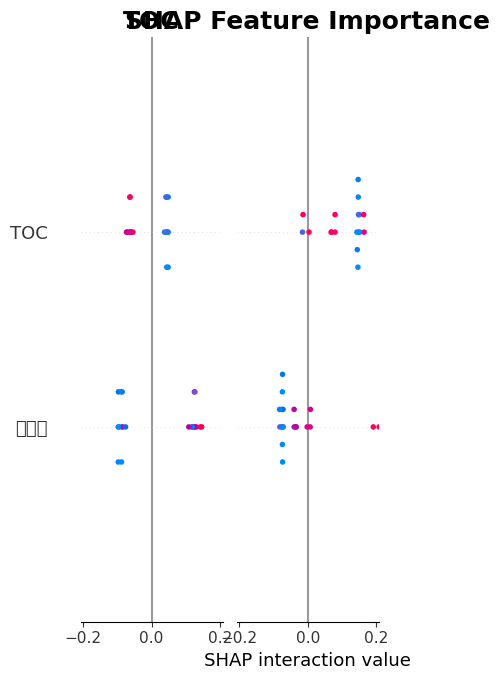

In [8]:
# 6. Random Forest Hypoxia Prediction
features_rf = ['TOC', '硫化物', 'ORP', 'pH', 'Depth', 'Temperature', 'Salinity']
target_rf = 'Hypoxia'

df_rf = annual_merge[features_rf + [target_rf]].dropna()
X_rf = df_rf[features_rf]
y_rf = df_rf[target_rf]

X_train, X_test, y_train, y_test = train_test_split(X_rf, y_rf, test_size=0.3, random_state=42, stratify=y_rf)

rf = RandomForestClassifier(n_estimators=200, max_depth=10, min_samples_leaf=5, random_state=42)
rf.fit(X_train, y_train)

y_pred = rf.predict(X_test)
y_prob = rf.predict_proba(X_test)[:, 1]

print("Random Forest Performance:")
print("Accuracy:", accuracy_score(y_test, y_pred))
print("AUC-ROC:", roc_auc_score(y_test, y_prob))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

plt.figure(figsize=(6, 5))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues',
            xticklabels=['Normoxic', 'Hypoxic'], yticklabels=['Normoxic', 'Hypoxic'])
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

explainer = shap.TreeExplainer(rf)
shap_values = explainer.shap_values(X_test)
if isinstance(shap_values, list):
    shap_vals = shap_values[1]
else:
    shap_vals = shap_values
shap.summary_plot(shap_vals, X_test, plot_type="bar", show=False)
plt.title("SHAP Feature Importance")
plt.show()
